# 作业 3：NumPy、Matplotlib 与 pandas

**姓名：** 金晨曦　　**学号：** 20244081111　　**日期：** 2026-11-18

**运行环境：** conda 虚拟环境 `dpenv`（Python 3.11，NumPy 2.4、SciPy 1.17、Matplotlib 3.11、pandas 3.0）。

本 Notebook 依次完成半圆定律、Conway 生命游戏和 iris 数据集的 pandas 分析。随机过程固定种子；图表直接内嵌显示。

In [1]:
import hashlib
import os
import platform
import uuid

# 修改为自己的学号
STUDENT_ID = 20244081111

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")

[Conda 环境] dpenv
[学号]       20244081111
[机器指纹] 504894f62c9f33b0
[RUN_ID]   20244081111-504894f62c9f33b0


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

print("NumPy:", np.__version__, "| pandas:", pd.__version__)

NumPy: 2.4.6 | pandas: 3.0.6


## 一、围绕半圆定律

Wigner 矩阵是随机对称矩阵：对所有 `1 ≤ i ≤ j ≤ n`，独立地从均值为 0、方差为 `1/n` 的正态分布抽取 `Z_ij`，再令 `Z_ji = Z_ij`。随着 `n` 增大，标准化特征值的分布趋近半圆密度

$$
f(x)=\begin{cases}
\dfrac{1}{2\pi}\sqrt{4-x^2}, & |x|\le 2,\\[4pt]
0, & |x|>2.
\end{cases}
$$

### 1. `wigner_density(x)`

接收一个整数或浮点数，返回半圆密度在 `x` 处的值，返回浮点数；使用 `numpy.sqrt`，不使用 `math.sqrt`。为了后面画曲线，函数也接受 NumPy 数组。

In [3]:
def wigner_density(x):
    """返回半圆密度在 x 处的值；标量输入返回 float，数组输入返回 ndarray。"""
    x = np.asarray(x, dtype=float)
    inside = np.abs(x) <= 2
    values = np.where(
        inside,
        np.sqrt(np.maximum(4.0 - x ** 2, 0.0)) / (2.0 * np.pi),
        0.0,
    )
    if values.ndim == 0:
        return float(values)
    return values

In [4]:
print("wigner_density(0)       =", wigner_density(0))
print("wigner_density(1.5)     =", wigner_density(1.5))
print("wigner_density(2)       =", wigner_density(2))
print("wigner_density(2.5)     =", wigner_density(2.5))
print("wigner_density(np.int64(1))   =", wigner_density(np.int64(1)))
print("wigner_density(np.float64(0.5)) =", wigner_density(np.float64(0.5)))
print("wigner_density([-2,-1,0,1,2,2.5]) =", wigner_density(np.array([-2, -1, 0, 1, 2, 2.5])))

wigner_density(0)       = 0.3183098861837907
wigner_density(1.5)     = 0.2105421996738962
wigner_density(2)       = 0.0
wigner_density(2.5)     = 0.0
wigner_density(np.int64(1))   = 0.27566444771089604
wigner_density(np.float64(0.5)) = 0.30820222203074993
wigner_density([-2,-1,0,1,2,2.5]) = [0.         0.27566445 0.31830989 0.27566445 0.         0.        ]


**说明：** `|x| ≤ 2` 时返回 `sqrt(4-x^2)/(2π)`，`|x| > 2` 时返回 0。`x = 0` 处密度为 `1/π ≈ 0.3183`，`x = ±2` 处为 0。函数用 `np.asarray` 统一处理 Python 标量和 NumPy 标量；对标量返回 Python `float`，对数组返回 `ndarray` 以便绘图。

### 2. `generate_wigner(n)`

接收正整数 `n`，返回随机生成的 `n × n` Wigner 矩阵；输入不是整数或不是正数时抛出合适的异常。

In [5]:
def generate_wigner(n):
    """生成 n×n 的 Wigner 矩阵（对称，上三角元素 ~ N(0, 1/n)）。"""
    if isinstance(n, bool) or not isinstance(n, (int, np.integer)):
        raise TypeError("n 必须是整数")
    if n <= 0:
        raise ValueError("n 必须是正整数")

    n = int(n)
    upper = np.random.normal(loc=0.0, scale=np.sqrt(1.0 / n), size=(n, n))
    # 保留上三角（含对角线），把严格上三角复制到下三角，得到对称矩阵
    return np.triu(upper) + np.triu(upper, 1).T

In [6]:
np.random.seed(202440811)
Z = generate_wigner(4)
print("Z =")
print(Z)
print("shape:", Z.shape, "| symmetric:", np.allclose(Z, Z.T))
print("diagonal:", np.diag(Z))

for bad in [0, -3, 2.5, "4", True]:
    try:
        generate_wigner(bad)
    except (TypeError, ValueError) as exc:
        print(f"generate_wigner({bad!r}) -> {type(exc).__name__}: {exc}")

Z =
[[-0.00276714  0.01505826 -0.09605378 -0.58072907]
 [ 0.01505826 -0.47100596 -0.09513817  0.38759435]
 [-0.09605378 -0.09513817 -0.18072596 -1.16458149]
 [-0.58072907  0.38759435 -1.16458149  0.32494264]]
shape: (4, 4) | symmetric: True
diagonal: [-0.00276714 -0.47100596 -0.18072596  0.32494264]
generate_wigner(0) -> ValueError: n 必须是正整数
generate_wigner(-3) -> ValueError: n 必须是正整数
generate_wigner(2.5) -> TypeError: n 必须是整数
generate_wigner('4') -> TypeError: n 必须是整数
generate_wigner(True) -> TypeError: n 必须是整数


**说明：** 先生成与 `Z` 同形状的上三角正态矩阵，再用 `np.triu(upper) + np.triu(upper, 1).T` 把严格上三角复制到下三角，保证 `Z_ij = Z_ji`。对角线元素也只抽取一次。非整数（如 `2.5`、字符串）抛 `TypeError`，非正数（0、负数）抛 `ValueError`，布尔值也按类型错误处理。

### 3. `get_spectrum(matrix)`

接收 NumPy 矩阵或二维 NumPy 数组，返回全部特征值组成的 NumPy 数组，按非递减顺序排列；不检查输入类型。

In [7]:
def get_spectrum(matrix):
    """返回矩阵全部特征值，按非递减顺序排列。"""
    return np.sort(np.linalg.eigvalsh(np.asarray(matrix)))

In [8]:
np.random.seed(202440811)
Z = generate_wigner(5)
eigs = get_spectrum(Z)
print("特征值:", eigs)
print("长度:", len(eigs), "| 非递减:", np.all(np.diff(eigs) >= 0))

特征值: [-1.3514232  -0.84714769 -0.30565055  0.60062681  1.22179238]
长度: 5 | 非递减: True


**说明：** Wigner 矩阵是实对称矩阵，`np.linalg.eigvalsh` 专门求实对称矩阵的特征值，数值上比通用 `eigvals` 更稳定；`np.sort` 保证返回结果按非递减顺序排列。输入为 `np.matrix` 时先用 `np.asarray` 转成普通二维数组。

### 4. 四个 `n` 值的特征值分布与半圆密度

对 `n = 100, 200, 500, 1000`，每个子图用蓝色标准化直方图展示特征值，并叠加红色半圆密度曲线。

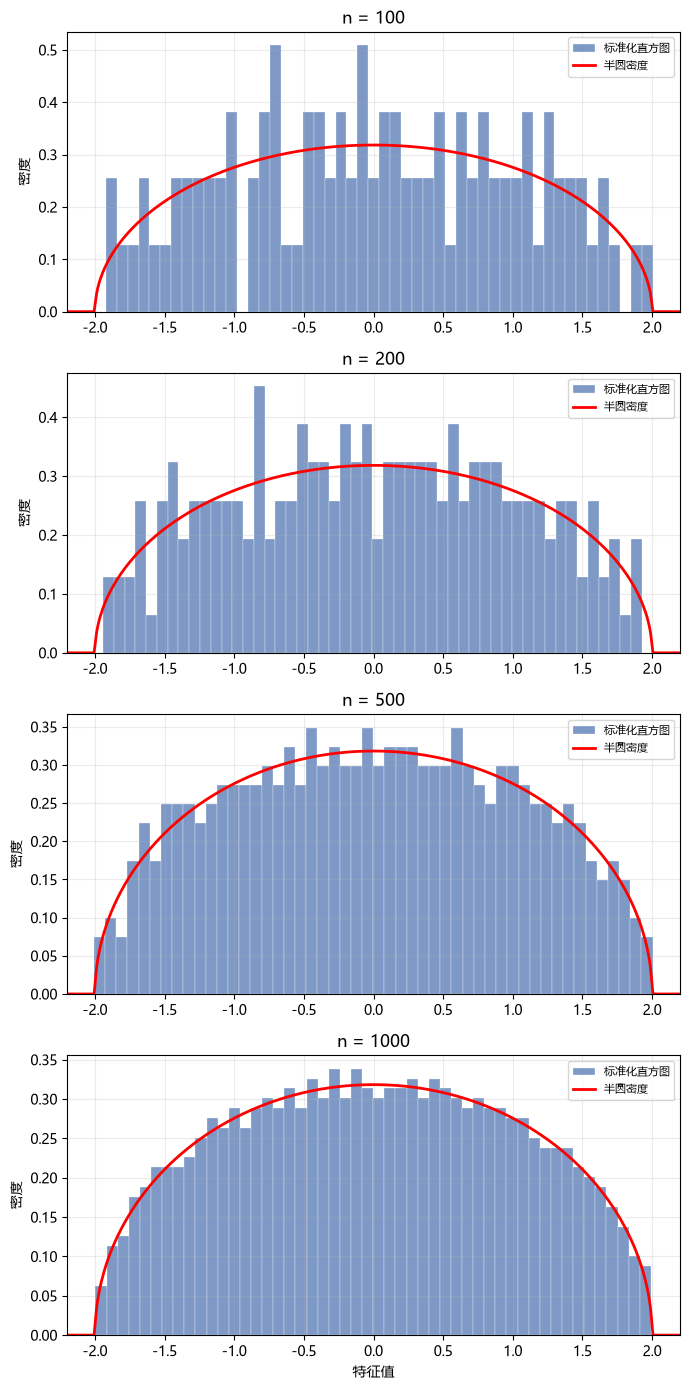

In [9]:
np.random.seed(202440811)
ns = [100, 200, 500, 1000]
x_grid = np.linspace(-2.2, 2.2, 500)

fig, axes = plt.subplots(4, 1, figsize=(7, 14))
for ax, n in zip(axes, ns):
    Z = generate_wigner(n)
    eigs = get_spectrum(Z)

    ax.hist(eigs, bins=50, density=True, color="#4C72B0",
            alpha=0.72, edgecolor="white", linewidth=0.3, label="标准化直方图")
    ax.plot(x_grid, wigner_density(x_grid), color="red", linewidth=2, label="半圆密度")
    ax.set_xlim(-2.2, 2.2)
    ax.set_title(f"n = {n}")
    ax.set_ylabel("密度")
    ax.grid(alpha=0.25)
    ax.legend(loc="upper right", fontsize=8)

axes[-1].set_xlabel("特征值")
plt.tight_layout()
plt.show()

**读图说明：** `n` 较小时（如 100），直方图有明显涨落，边缘也不够平滑；随着 `n` 增大，直方图的轮廓逐渐稳定，`n = 500` 和 `n = 1000` 时已经与红色半圆曲线吻合得较好。可以认为 `n` 达到约 500 时，半圆密度能较好地拟合特征值分布；`n = 1000` 的拟合更平滑。

### 可选：Kolmogorov–Smirnov 检验

用半圆密度的累积分布函数与经验分布比较，计算 KS 统计量。统计量越小，说明经验分布越接近半圆分布。

In [10]:
def wigner_cdf(x):
    """半圆密度的累积分布函数，支持标量和数组。"""
    x = np.asarray(x, dtype=float)
    middle = (0.5
              + x * np.sqrt(np.maximum(4.0 - x ** 2, 0.0)) / (4.0 * np.pi)
              + np.arcsin(np.clip(x / 2.0, -1.0, 1.0)) / np.pi)
    values = np.where(x <= -2, 0.0, np.where(x >= 2, 1.0, middle))
    if values.ndim == 0:
        return float(values)
    return values

In [11]:
np.random.seed(202440811)
print("n     KS 统计量    p 值")
for n in ns:
    eigs = get_spectrum(generate_wigner(n))
    ks_stat, p_value = stats.kstest(eigs, wigner_cdf)
    print(f"{n:<5} {ks_stat:<12.4f} {p_value:.4g}")

n     KS 统计量    p 值
100   0.0216       1
200   0.0120       1
500   0.0066       1
1000  0.0031       1


**说明：** KS 统计量随 `n` 增大总体下降，说明特征值分布越来越接近半圆分布；`p` 值只作为参考，因为这里的样本是同一矩阵的特征值，并非完全独立的观测。该检验是题目中的可选任务。

## 二、Conway 的生命游戏

棋盘用 `m × n` 的 NumPy 二维数组表示：1 为活细胞，0 为死细胞。每个细胞有 8 个邻居，边界环绕。所有细胞按原棋盘同时更新：

- 活细胞邻居少于 2 个：死亡；
- 活细胞有 2 或 3 个邻居：存活；
- 活细胞邻居多于 3 个：死亡；
- 死细胞恰好有 3 个邻居：复活；
- 其他死细胞保持死亡。

### 1. `is_valid_board(board)`

判断输入是否为有效棋盘：NumPy `ndarray`、二维、元素仅为 0 或 1，返回 Python 布尔值。

In [12]:
def is_valid_board(board):
    """判断 board 是否为有效的生命游戏棋盘。"""
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2:
        return False
    return bool(np.all((board == 0) | (board == 1)))

In [13]:
print("is_valid_board:")
for board in [
    np.array([[0, 1], [1, 0]]),
    np.array([[0, 2], [1, 0]]),
    np.array([0, 1, 0]),
    np.array([[[1]]]),
    [[0, 1], [1, 0]],
]:
    print(f"  {board!r:32} -> {is_valid_board(board)}")

is_valid_board:
  array([[0, 1],
       [1, 0]])   -> True
  array([[0, 2],
       [1, 0]])   -> False
  array([0, 1, 0])                 -> False
  array([[[1]]])                   -> False
  [[0, 1], [1, 0]]                 -> False


**说明：** 先检查类型是否为 `np.ndarray`，再检查 `ndim == 2`，最后用 `(board == 0) | (board == 1)` 判断每个元素是否只取 0 或 1。普通 Python 列表、一维数组、三维数组和含 2 的数组都返回 `False`；返回值用 `bool()` 转成 Python 布尔值。

### 2. `gol_step(board)`

接收 `m × n` 棋盘，返回下一步的棋盘；先检查合法性，无效时抛出异常；计算邻居时必须使用原棋盘。

In [14]:
def gol_step(board):
    """返回生命游戏棋盘的下一步；边界环绕。"""
    if not is_valid_board(board):
        raise ValueError("board 必须是二维且元素仅为 0 或 1 的 NumPy 数组")

    neighbors = np.zeros(board.shape, dtype=int)
    for dr in (-1, 0, 1):
        for dc in (-1, 0, 1):
            if dr == 0 and dc == 0:
                continue
            neighbors += np.roll(np.roll(board, dr, axis=0), dc, axis=1)

    alive = board == 1
    next_board = (neighbors == 3) | (alive & (neighbors == 2))
    return next_board.astype(int)

In [15]:
blinker = np.zeros((5, 5), dtype=int)
blinker[2, 1:4] = 1

print("初始棋盘:")
print(blinker)
print("下一步:")
print(gol_step(blinker))

for bad in [[[1, 0], [0, 1]], np.array([1, 0]), np.array([[1, 2]])]:
    try:
        gol_step(bad)
    except ValueError as exc:
        print(f"无效输入 -> ValueError: {exc}")

初始棋盘:
[[0 0 0 0 0]
 [0 0 0 0 0]
 [0 1 1 1 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]
下一步:
[[0 0 0 0 0]
 [0 0 1 0 0]
 [0 0 1 0 0]
 [0 0 1 0 0]
 [0 0 0 0 0]]
无效输入 -> ValueError: board 必须是二维且元素仅为 0 或 1 的 NumPy 数组
无效输入 -> ValueError: board 必须是二维且元素仅为 0 或 1 的 NumPy 数组
无效输入 -> ValueError: board 必须是二维且元素仅为 0 或 1 的 NumPy 数组


**说明：** 用 `np.roll` 在行、列方向分别平移，再把 8 个方向的结果相加，得到每个格子的活邻居数；`np.roll` 天然实现上下、左右和四个对角的环绕边界。下一步条件写成 `neighbors == 3`（死细胞复活或活细胞存活）或 `alive & (neighbors == 2)`（活细胞有两个邻居时存活）。整个 `neighbors` 只由原 `board` 计算，因此更新是同时进行的。水平三连的“闪烁器”下一步会变成竖直三连，符合经典结果。

### 3. `draw_gol_board(board)`

把棋盘画成 `m × n` 个方格：活细胞黑色，死细胞白色；不显示网格线、轴标签或轴刻度。

In [16]:
def draw_gol_board(board):
    """把棋盘画成黑白方格图；活细胞黑色，死细胞白色。"""
    if not is_valid_board(board):
        raise ValueError("board 必须是二维且元素仅为 0 或 1 的 NumPy 数组")

    plt.figure(figsize=(5, 5))
    plt.imshow(board, cmap=plt.get_cmap("gray_r"), interpolation="nearest")
    plt.xticks([])
    plt.yticks([])
    plt.axis("off")
    plt.show()

初始滑翔机:


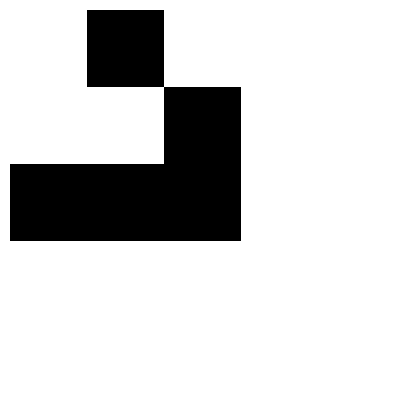

下一步:


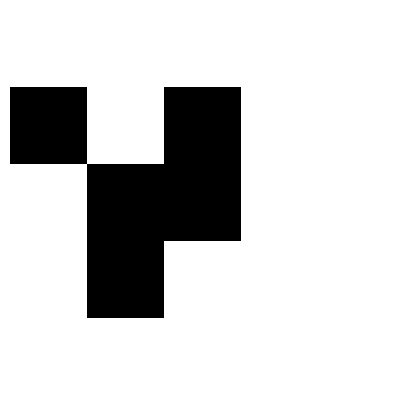

In [17]:
glider = np.array([
    [0, 1, 0, 0, 0],
    [0, 0, 1, 0, 0],
    [1, 1, 1, 0, 0],
    [0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0],
])

print("初始滑翔机:")
draw_gol_board(glider)
print("下一步:")
draw_gol_board(gol_step(glider))

**说明：** `gray_r` 是反向灰度色图，0 映射为白色、1 映射为黑色；`interpolation="nearest"` 保证每个格子是纯色方块。`plt.xticks([])`、`plt.yticks([])` 去掉刻度和标签，`plt.axis("off")` 去掉坐标轴和边框，因此图中只保留黑白方格。上面分别画出了滑翔机的初始状态和下一步。

## 三、使用 pandas DataFrame

使用标准 Iris 数据集 `iris.csv`（含 `Id`、四个测量列和 `Species` 列）。按题目要求用默认的 0-based 行索引处理第 35、38 个数据行（索引 34、37）。

### 1. 读取数据并回答基本问题

用 pandas 读入 CSV，第一行为列标题；回答数据点数量、各列数据类型、列名、花卉种类数。

In [18]:
df = pd.read_csv("iris.csv")

print("原始 DataFrame 形状:", df.shape)
print("原始列名:", df.columns.tolist())
print("\n各列数据类型:")
print(df.dtypes)
print("\n花卉种类数:", df["Species"].nunique())
print(df["Species"].value_counts())

# Id 只是行标识，不是测量特征；去掉后保留 4 个测量列 + Species
df = df.drop(columns=["Id"])
df["Species"] = df["Species"].str.replace("Iris-", "", regex=False)

print("\n用于分析的列名:", df.columns.tolist())
print("分析用 DataFrame 形状:", df.shape)
print(df.head())

原始 DataFrame 形状: (150, 6)
原始列名: ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']

各列数据类型:
Id                 int64
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species              str
dtype: object

花卉种类数: 3
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

用于分析的列名: ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']
分析用 DataFrame 形状: (150, 5)
   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm Species
0            5.1           3.5            1.4           0.2  setosa
1            4.9           3.0            1.4           0.2  setosa
2            4.7           3.2            1.3           0.2  setosa
3            4.6           3.1            1.5           0.2  setosa
4            5.0           3.6            1.4           0.2  setosa


**回答：**

- 数据集共有 **150 个数据点**（150 行），CSV 第一行是列标题。
- 原始文件有 6 列：`Id`、`SepalLengthCm`、`SepalWidthCm`、`PetalLengthCm`、`PetalWidthCm`、`Species`。`Id` 是行标识，分析时去掉；四个测量列都是 `float64`，`Species` 是字符串（`object`）。
- 数据中有 **3 种花卉**：`setosa`、`versicolor`、`virginica`，每种 50 条。
- 五个分析列对应花卉种类，以及萼片长度、萼片宽度、花瓣长度、花瓣宽度四项测量。

### 2. 修正第 35、38 个数据行

第 35 行（索引 34）改为 `4.9, 3.1, 1.5, 0.2, "setosa"`；第 38 行（索引 37）改为 `4.9, 3.6, 1.4, 0.1, "setosa"`。

In [19]:
measure_cols = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]

print("修改前（索引 34、37）:")
print(df.loc[[34, 37]])

# 第 35 个数据行：索引 34，原第四项测量有误
df.loc[34, measure_cols] = [4.9, 3.1, 1.5, 0.2]
df.loc[34, "Species"] = "setosa"

# 第 38 个数据行：索引 37，原第二、三项测量有误
df.loc[37, measure_cols] = [4.9, 3.6, 1.4, 0.1]
df.loc[37, "Species"] = "setosa"

print("\n修改后（索引 34、37）:")
print(df.loc[[34, 37]])

修改前（索引 34、37）:
    SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm Species
34            4.9           3.1            1.5           0.1  setosa
37            4.9           3.1            1.5           0.1  setosa

修改后（索引 34、37）:
    SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm Species
34            4.9           3.1            1.5           0.2  setosa
37            4.9           3.6            1.4           0.1  setosa


**说明：** 原文件索引 34 的 `PetalWidthCm` 为 0.1，按题目改为 0.2；索引 37 的 `SepalWidthCm` 和 `PetalLengthCm` 分别为 3.1、1.5，按题目改为 3.6、1.4。两行都改为 `setosa`。使用 `.loc` 按标签定位，避免链式赋值。

### 3. 添加 `Petal.Ratio` 和 `Sepal.Ratio`

`Petal.Ratio` 为花瓣长度除以花瓣宽度，`Sepal.Ratio` 为萼片长度除以萼片宽度。

In [20]:
df["Petal.Ratio"] = (df["PetalLengthCm"] / df["PetalWidthCm"]).round(6)
df["Sepal.Ratio"] = (df["SepalLengthCm"] / df["SepalWidthCm"]).round(6)

print(df[["Species", "Petal.Ratio", "Sepal.Ratio"]].head())
print("\n两列新特征的描述统计:")
print(df[["Petal.Ratio", "Sepal.Ratio"]].describe())

  Species  Petal.Ratio  Sepal.Ratio
0  setosa          7.0     1.457143
1  setosa          7.0     1.633333
2  setosa          6.5     1.468750
3  setosa          7.5     1.483871
4  setosa          7.0     1.388889

两列新特征的描述统计:
       Petal.Ratio  Sepal.Ratio
count   150.000000   150.000000
mean      4.310500     1.953681
std       2.489648     0.400480
min       2.125000     1.268293
25%       2.802381     1.546188
50%       3.300000     2.032291
75%       4.666667     2.224910
max      15.000000     2.961538


**说明：** 直接用列相除生成新列，pandas 会按行对齐。`Petal.Ratio` 和 `Sepal.Ratio` 都是无量纲的比值，便于比较不同花朵的形状；比值保留 6 位小数，避免 `iris_corrected.csv` 中出现 `6.999999999999999` 这类浮点尾数。`describe()` 给出样本数、均值、标准差、最小值、四分位数和最大值。

### 4. 保存为 `iris_corrected.csv`

将更正并扩展后的 DataFrame 保存为 `iris_corrected.csv`，随作业提交。

In [21]:
output_path = "iris_corrected.csv"
df.to_csv(output_path, index=False)

print("已保存:", output_path)
print("保存形状:", df.shape)
print("读回检查:")
print(pd.read_csv(output_path).head())

已保存: iris_corrected.csv
保存形状: (150, 7)
读回检查:
   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm Species  \
0            5.1           3.5            1.4           0.2  setosa   
1            4.9           3.0            1.4           0.2  setosa   
2            4.7           3.2            1.3           0.2  setosa   
3            4.6           3.1            1.5           0.2  setosa   
4            5.0           3.6            1.4           0.2  setosa   

   Petal.Ratio  Sepal.Ratio  
0          7.0     1.457143  
1          7.0     1.633333  
2          6.5     1.468750  
3          7.5     1.483871  
4          7.0     1.388889  


**说明：** `to_csv(..., index=False)` 不把 pandas 的行索引写入文件，保证 CSV 只有分析用的列；读回后形状与内存中的 DataFrame 一致。文件保存在当前 Notebook 所在目录，随作业一起提交。

### 5. 按花卉种类分组汇总

按 `Species` 分组，一次计算 `Petal.Ratio` 和 `Sepal.Ratio` 的平均值、中位数、最小值、最大值和标准差。

In [22]:
ratio_cols = ["Petal.Ratio", "Sepal.Ratio"]
summary = df.groupby("Species")[ratio_cols].agg(["mean", "median", "min", "max", "std"])

print(summary)

           Petal.Ratio                                     Sepal.Ratio  \
                  mean    median       min   max       std        mean   
Species                                                                  
setosa        6.908000  7.000000  2.666667  15.0  2.854545    1.470188   
versicolor    3.242837  3.240385  2.666667   4.1  0.312456    2.160402   
virginica     2.780662  2.666667  2.125000   4.0  0.407367    2.230453   

                                                    
              median       min       max       std  
Species                                             
setosa      1.463063  1.268293  1.956522  0.118750  
versicolor  2.161290  1.764706  2.818182  0.228658  
virginica   2.169541  1.823529  2.961538  0.246992  


**说明：** `groupby("Species")` 按花卉种类分组，`[ratio_cols]` 选中两个比值列，`agg([...])` 一次得到五个统计量。结果列是 MultiIndex：第一层是特征名，第二层是统计量。可以看出 `setosa` 的花瓣长宽比明显大于另外两类（约 6.91，而 versicolor/virginica 约 3.24/2.78）；萼片长宽比的组间差异相对较小（setosa 约 1.47，另外两类约 2.16/2.23）。

## 小结

- 半圆定律部分实现了 `wigner_density`、`generate_wigner`、`get_spectrum`，并用四个子图展示了 `n = 100, 200, 500, 1000` 时特征值分布逐渐逼近半圆密度；`n` 约 500 时拟合已经较好。
- 生命游戏部分实现了棋盘合法性检查、带环绕边界的同步更新和黑白方格绘制。
- pandas 部分读取并清理 Iris 数据，修正第 35、38 行，构造两个比值特征，保存 `iris_corrected.csv`，并按种类汇总统计量。